# Fine-tuning Gemma 4-E4B

In [1]:
!nvidia-smi

Fri Jul 24 19:56:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P0             49W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [1]:
!pip install trl bitsandbytes peft

In [3]:
import math


import torch
from datasets import load_dataset
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
)
from peft import LoraConfig, TaskType
from trl import SFTTrainer, SFTConfig

# -----------------------------------------------
# 1. Model and Tokenizer
# -----------------------------------------------

model_name = "google/gemma-4-E4B-it"

# 4-bit quantization configuration (QLoRA)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
tokenizer.model_max_length = 1024 # Reduced model_max_length to conserve memory

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

# Note: prepare_model_for_kbit_training() is no longer called here.
# SFTTrainer handles quantized-model preparation internally when
# peft_config is provided (PEFT >= 0.12).

# -----------------------------------------------
# 2. LoRA Configuration
# -----------------------------------------------

lora_config = LoraConfig(
    r=4, # Reduced LoRA rank
    lora_alpha=4, # Adjusted with r for more conservative updates
    target_modules="all-linear",
    # E4B is multimodal: keep the adapters out of the vision/audio towers
    exclude_modules=r".*(vision|audio).*",
    lora_dropout=0.2,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
)

# -----------------------------------------------
# 3. Dataset
# -----------------------------------------------

# Load the synthetic GPT-120B medical QA dataset.
# Schema: {"instruction": str, "input": str, "output": str, "metadata": {...}}
raw_dataset = load_dataset(
    "json",
    data_files="medical_qa_synthetic_hf.jsonl",
    split="train",
)

def format_example(example):
    """
    Convert instruction/output pairs into Gemma 4 chat-template format.
    If the optional 'input' field has content it is appended to the instruction
    as additional context.  The result is stored in a 'text' column that
    SFTTrainer will use directly for training.
    """
    user_content = example["instruction"]
    if example.get("input", "").strip():
        user_content = f"{example['instruction']}\n\n{example['input']}"

    messages = [
        {"role": "user",      "content": user_content},
        {"role": "assistant", "content": example["output"]},
    ]
    return {
        "text": tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False,
        )
    }

# Apply the chat template and drop the original columns
dataset = raw_dataset.map(
    format_example,
    remove_columns=raw_dataset.column_names,
)

# Create a 90/10 train/validation split (seed fixed for reproducibility)
split = dataset.train_test_split(test_size=0.1, seed=42)
train_dataset = split["train"]
eval_dataset  = split["test"]
eval_dataset.to_json("eval_dataset.jsonl", orient="records", lines=True)
print(f"Wrote Eval Dataset")
print(f"Training examples:   {len(train_dataset)}")
print(f"Validation examples: {len(eval_dataset)}")
print(f"Sample formatted text (first 300 chars):\n{train_dataset[0]['text'][:300]}")

# -----------------------------------------------
# 4. Training Configuration
# -----------------------------------------------

# Compute warmup_steps from dataset size (replaces deprecated warmup_ratio).
# effective_batch = per_device_batch * gradient_accumulation_steps
# total_optimizer_steps = ceil(train_size / effective_batch) * epochs
effective_batch = 8 * 8  # per_device_train_batch_size * gradient_accumulation_steps (Changed to 8)
total_steps = math.ceil(len(train_dataset) / effective_batch) * 5 # Reduced num_train_epochs for calculation
warmup_steps = max(1, int(0.1 * total_steps))
print(f"Total optimizer steps: {total_steps}  |  Warmup steps: {warmup_steps}")

# SFTConfig = TrainingArguments + SFT-specific args (e.g. dataset_text_field).
# In TRL >= 0.9 these args moved from SFTTrainer.__init__() to SFTConfig.
training_args = SFTConfig(
    output_dir="./results/medical-qa-v1",

    # SFT-specific
    dataset_text_field="text",

    # Training duration
    num_train_epochs=20, # Reduced number of epochs further

    # Batch size — A100/H100 has ample VRAM; larger batches improve throughput.
    # Effective train batch = 8 * 8 = 64.
    per_device_train_batch_size=8,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=8,

    # Learning rate
    learning_rate=1e-4, # Changed to 1e-4
    lr_scheduler_type="cosine",
    warmup_steps=warmup_steps,

    # Regularization
    weight_decay=0.05, # Increased weight decay
    max_grad_norm=0.3,

    # Precision — A100/H100 has native BF16 tensor cores
    bf16=True,

    # Logging
    logging_steps=5,
    logging_first_step=True,
    report_to="tensorboard",

    # Evaluation
    eval_strategy="steps",
    eval_steps=5,

    # Checkpointing
    save_strategy="steps",
    save_steps=50,
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",

    # Memory optimization
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    optim="paged_adamw_8bit",
)

# -----------------------------------------------
# 5. Data Collator
# -----------------------------------------------

# None needed! TRL's default collator pads input_ids and labels
# correctly. (Gemma 3 required a custom collator here to inject
# token_type_ids into every batch -- Gemma 4 does not, so if you are
# adapting this notebook back to Gemma 3, that is the piece to restore.)

# -----------------------------------------------
# 7. Trainer
# -----------------------------------------------

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    processing_class=tokenizer,
    peft_config=lora_config
)

# Verify the configuration
trainable_params = sum(p.numel() for p in model.parameters()
                       if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"\nTrainable parameters: {trainable_params:,}")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable %:          {100 * trainable_params / total_params:.4f}%")

# -----------------------------------------------
# 8. Train
# -----------------------------------------------

print("\nStarting training...")
trainer.train()

# -----------------------------------------------
# 9. Save the adapter
# -----------------------------------------------

trainer.save_model("./adapters/medical-qa-v1")
tokenizer.save_pretrained("./adapters/medical-qa-v1")

print("\nTraining complete. Adapter saved to ./adapters/medical-qa-v1")

Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Wrote Eval Dataset
Training examples:   549
Validation examples: 62
Sample formatted text (first 300 chars):
<bos><|turn>user
When should someone with major depressive disorder seek emergency medical care?<turn|>
<|turn>model
CLINICAL CONSIDERATIONS: Individuals with major depression are at risk for rapid deterioration, especially when suicidal thoughts, plans, or intent arise. Emergency care is also warra
Total optimizer steps: 45  |  Warmup steps: 4


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 1, 'bos_token_id': 2, 'pad_token_id': 1}.



Trainable parameters: 9,719,808
Total parameters:     5,733,377,312
Trainable %:          0.1695%

Starting training...


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
5,4.851769,4.680167,0.305327,126276.000000,0.558319
10,4.540521,3.944566,0.406324,244848.000000,0.563820
15,3.503042,2.848801,0.728496,372360.000000,0.565393
20,2.576637,2.287779,1.097064,488877.000000,0.569030
25,2.129966,1.917184,1.251359,616985.000000,0.592173
30,1.784619,1.662530,1.377687,733657.000000,0.616308
35,1.577829,1.511069,1.391758,861425.000000,0.634263
40,1.442025,1.410021,1.371259,978763.000000,0.648840
45,1.367001,1.327802,1.287698,1095875.000000,0.658007
50,1.271149,1.263643,1.165278,1224118.000000,0.668122



Training complete. Adapter saved to ./adapters/medical-qa-v1


# View results with TensorBoard

In [ ]:
%load_ext tensorboard
%tensorboard --logdir ./results/medical-qa-v1

In [ ]:
!pip install wandb
!wandb login

# Zip and download adapter

In [5]:
import os
from google.colab import files

output_filename = "medical-qa-v1-adapter.zip"
zip_command = f"zip -r {output_filename} ./adapters/medical-qa-v1"

os.system(zip_command)
files.download(output_filename)

print(f"Successfully created and downloaded {output_filename}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Successfully created and downloaded medical-qa-v1-adapter.zip


# Plot Training Results

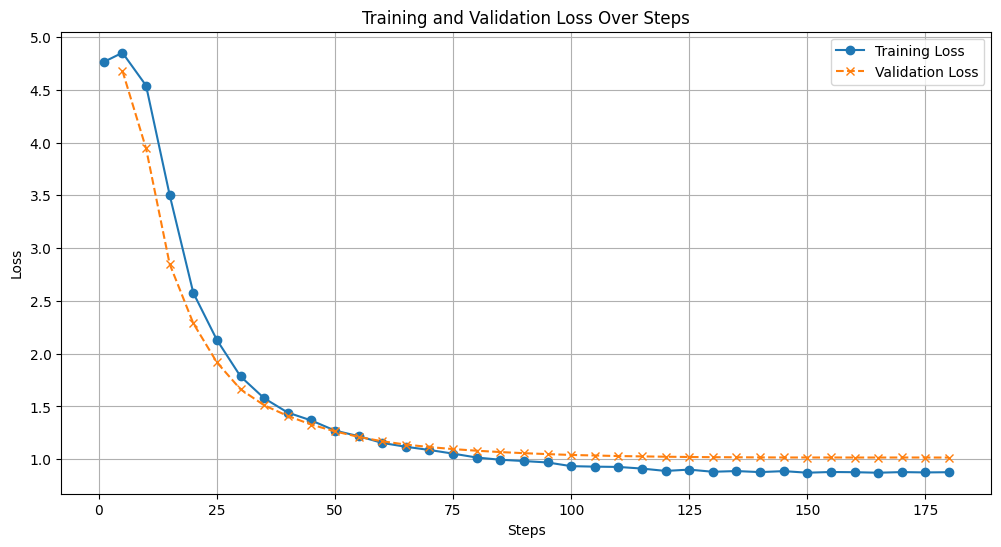

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract log history from the trainer
logs = trainer.state.log_history

# Filter for training and evaluation steps
train_metrics = [log for log in logs if 'loss' in log and 'learning_rate' in log]
eval_metrics = [log for log in logs if 'eval_loss' in log]

# Create DataFrames for easier plotting
train_df = pd.DataFrame(train_metrics)
eval_df = pd.DataFrame(eval_metrics)

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(train_df['step'], train_df['loss'], label='Training Loss', marker='o', linestyle='-')
plt.plot(eval_df['step'], eval_df['eval_loss'], label='Validation Loss', marker='x', linestyle='--')

plt.title('Training and Validation Loss Over Steps')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Load and Test the model with adapter

In [8]:
%pip install -U torchao
# (stale torchao versions in shared environments break model loading;
# restart the runtime if this upgrades anything)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 100.2 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [ ]:
# Free the training run's GPU memory first (see Chapter 3!) --
# without this, the second copy of the model spills off the GPU and
# generate() fails with "Tensor on device meta" errors.
import gc
import torch

for name in ("trainer", "model"):
    if name in dir():
        del globals()[name]
gc.collect()
torch.cuda.empty_cache()

from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel

model_name = "google/gemma-4-E4B-it"

# Load the base in 4-bit for inference: ~6GB instead of ~16GB, so
# everything stays on the GPU
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map="auto",
)
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Attach the LoRA adapter. Note: no merge_and_unload() here -- merging
# isn't supported into 4-bit weights, and the adapter runs alongside
# the quantized base with negligible overhead.
model = PeftModel.from_pretrained(model, "./adapters/medical-qa-v1")
model.eval()


In [10]:
# Format a test prompt using the chat template
messages = [
    {"role": "user", "content": "What are the common symptoms of hypothyroidism?"},
]

input_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

inputs = tokenizer(input_text, return_tensors="pt").to(model.device)

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=512,
        temperature=0.7,
        top_p=0.9,
        do_sample=True,
    )

response = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True,
)
print(response)

RuntimeError: Tensor on device meta is not on the expected device cuda:0!

# Try a few prompts with and without the adapter

In [ ]:
# Compare base vs fine-tuned WITHOUT loading a second copy of the model.
# PeftModel can disable its adapter on the fly, so one 4-bit base serves
# as both models -- half the memory, no meta-device spills.
import torch

medical_qa_prompts = [
    "What are the common symptoms of influenza?",
    "Explain the role of insulin in the human body.",
    "What is hypertension and how is it managed?",
    "Describe the benefits of regular exercise for cardiovascular health.",
    "What are the signs of a severe allergic reaction and what should be done?"
]

def generate_response(prompt_text):
    messages = [{"role": "user", "content": prompt_text}]
    input_text = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True,
    )
    inputs = tokenizer(input_text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=256,
            temperature=0.7,
            top_p=0.9,
            do_sample=True,
        )
    return tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True,
    )

print("\n--- Comparing Base Model vs. Fine-tuned Model ---\n")

for i, prompt in enumerate(medical_qa_prompts):
    print(f"\n--- Prompt {i+1} ---")
    print(f"Question: {prompt}")

    # Base model: temporarily switch the adapter off
    with model.disable_adapter():
        base_response = generate_response(prompt)
    print("\nBase Model Response:")
    print(base_response)

    # Fine-tuned: adapter active (the default)
    finetuned_response = generate_response(prompt)
    print("\nFine-tuned Model Response:")
    print(finetuned_response)
    print("\n" + "=" * 80)


# Train with Unsloth

In [ ]:
!pip install unsloth

In [ ]:
"""
FineTuneGemma_unsloth.py
========================

Unsloth version of the Chapter 8 medical Q&A fine-tuning script.

This file is a drop-in alternative to FineTuneGemma.ipynb that uses the
Unsloth library (https://github.com/unslothai/unsloth) to train a
LoRA / QLoRA adapter on top of google/gemma-4-E4B-it.

Compared to the standard Hugging Face stack used in the notebook, Unsloth:

  * Loads the model through FastLanguageModel.from_pretrained, which
    applies custom Triton kernels for attention and the LoRA forward /
    backward passes.
  * Attaches LoRA adapters via FastLanguageModel.get_peft_model
    (no separate LoraConfig + peft_config= argument to SFTTrainer).
  * Produces roughly 2x faster training and ~60% less peak VRAM on a
    single consumer GPU.

Everything else (data pipeline, chat template, the SFTConfig
hyperparameters, and the trainer call) is intentionally
identical to the notebook so you can compare the two runs directly.

Prerequisites
-------------
    pip install "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
    pip install --no-deps trl peft accelerate bitsandbytes
    # medical_qa_synthetic_hf.jsonl must be in the working directory.

Run with
--------
    python FineTuneGemma_unsloth.py
"""

# -----------------------------------------------
# IMPORTANT: import unsloth BEFORE transformers / trl
# -----------------------------------------------
# Unsloth patches several classes inside transformers at import time.
# If you import transformers first, the patches are not applied and you
# lose the speed-up (and will get a warning).
from unsloth import FastLanguageModel

import math
import torch
from datasets import load_dataset
from trl import SFTTrainer, SFTConfig


# -----------------------------------------------
# 1. Model and Tokenizer (Unsloth)
# -----------------------------------------------
# FastLanguageModel.from_pretrained replaces:
#   - AutoTokenizer.from_pretrained
#   - BitsAndBytesConfig
#   - AutoModelForCausalLM.from_pretrained
#
# load_in_4bit=True turns on NF4 quantisation internally with the same
# bnb_4bit_quant_type="nf4" / double-quant settings used in the notebook.
# Unsloth also auto-selects bf16 or fp16 compute dtype based on the GPU.
MAX_SEQ_LENGTH = 1024   # matches tokenizer.model_max_length in the notebook

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/gemma-4-E4B-it",   # pre-optimised Unsloth mirror
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,                           # None = auto (bf16 on Ampere+, fp16 on T4)
    load_in_4bit=True,
)

# Same padding conventions as the notebook
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"


# -----------------------------------------------
# 2. LoRA Configuration (Unsloth)
# -----------------------------------------------
# FastLanguageModel.get_peft_model replaces the separate LoraConfig +
# peft_config= argument. The hyperparameters mirror the notebook:
#     r=4, lora_alpha=4, target_modules="all-linear", dropout=0.2
#
# Unsloth enables its own gradient-checkpointing variant
# ("unsloth") which is ~30% more memory-efficient than the standard
# HF implementation and is a drop-in replacement.
model = FastLanguageModel.get_peft_model(
    model,
    r=4,
    lora_alpha=4,
    target_modules="all-linear",
    lora_dropout=0.2,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=42,
    use_rslora=False,
    loftq_config=None,
)


# -----------------------------------------------
# 3. Dataset (identical to the notebook)
# -----------------------------------------------
raw_dataset = load_dataset(
    "json",
    data_files="medical_qa_synthetic_hf.jsonl",
    split="train",
)


def format_example(example):
    """
    Convert instruction/output pairs into Gemma 4 chat-template format.
    If the optional 'input' field has content, it is appended to the
    instruction as additional context. The result is stored in a 'text'
    column that SFTTrainer will use directly for training.
    """
    user_content = example["instruction"]
    if example.get("input", "").strip():
        user_content = f"{example['instruction']}\n\n{example['input']}"

    messages = [
        {"role": "user",      "content": user_content},
        {"role": "assistant", "content": example["output"]},
    ]
    return {
        "text": tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False,
        )
    }


dataset = raw_dataset.map(
    format_example,
    remove_columns=raw_dataset.column_names,
)

# 90/10 train/validation split (fixed seed for reproducibility)
split = dataset.train_test_split(test_size=0.1, seed=42)
train_dataset = split["train"]
eval_dataset = split["test"]

print(f"Training examples:   {len(train_dataset)}")
print(f"Validation examples: {len(eval_dataset)}")
print(f"Sample formatted text (first 300 chars):\n{train_dataset[0]['text'][:300]}")


# -----------------------------------------------
# 4. Training Configuration (identical to the notebook)
# -----------------------------------------------
# effective_batch = per_device_batch * gradient_accumulation_steps
# total_optimizer_steps = ceil(train_size / effective_batch) * epochs
NUM_EPOCHS = 20
PER_DEVICE_BATCH = 8
GRAD_ACCUM = 8

effective_batch = PER_DEVICE_BATCH * GRAD_ACCUM
total_steps = math.ceil(len(train_dataset) / effective_batch) * NUM_EPOCHS
warmup_steps = max(1, int(0.1 * total_steps))
print(f"Total optimizer steps: {total_steps}  |  Warmup steps: {warmup_steps}")

# Detect bf16 support at runtime. Ampere (CC 8.0) and newer GPUs have
# native bf16 tensor cores; Turing (T4, CC 7.5) does not and must use fp16.
bf16_supported = torch.cuda.is_available() and torch.cuda.is_bf16_supported()

training_args = SFTConfig(
    output_dir="./results/medical-qa-v1-unsloth",

    # SFT-specific
    dataset_text_field="text",
    max_seq_length=MAX_SEQ_LENGTH,
    packing=False,

    # Training duration
    num_train_epochs=NUM_EPOCHS,

    # Batch size
    per_device_train_batch_size=PER_DEVICE_BATCH,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=GRAD_ACCUM,

    # Learning rate
    learning_rate=1e-4,
    lr_scheduler_type="cosine",
    warmup_steps=warmup_steps,

    # Regularization
    weight_decay=0.05,
    max_grad_norm=0.3,

    # Mixed precision — auto-selected based on GPU capability
    bf16=bf16_supported,
    fp16=not bf16_supported,

    # Logging
    logging_steps=5,
    logging_first_step=True,
    report_to="tensorboard",

    # Evaluation
    eval_strategy="steps",
    eval_steps=5,

    # Checkpointing
    save_strategy="steps",
    save_steps=50,
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",

    # Memory / optimizer
    optim="paged_adamw_8bit",
    seed=42,
)


# -----------------------------------------------
# 5. Data Collator
# -----------------------------------------------
# None needed! TRL's default collator pads input_ids and labels
# correctly, and unlike Gemma 3, Gemma 4 does not require a
# token_type_ids injection for text-only training.


# -----------------------------------------------
# 6. Trainer
# -----------------------------------------------
# NOTE: we do NOT pass peft_config=... here. The model is already a
# PEFT model (wrapped by FastLanguageModel.get_peft_model above), so
# SFTTrainer should treat it as a pre-prepared model and train the
# existing adapters.
trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    processing_class=tokenizer,
)

# Verify the configuration
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"\nTrainable parameters: {trainable_params:,}")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable %:          {100 * trainable_params / total_params:.4f}%")


# -----------------------------------------------
# 7. Train
# -----------------------------------------------
print("\nStarting training with Unsloth...")
trainer.train()


# -----------------------------------------------
# 8. Save the adapter
# -----------------------------------------------
# trainer.save_model saves the LoRA adapter in the standard PEFT format,
# which means you can later load it without Unsloth installed, using:
#
#     from peft import PeftModel
#     base = AutoModelForCausalLM.from_pretrained("google/gemma-4-E4B-it", ...)
#     model = PeftModel.from_pretrained(base, "./adapters/medical-qa-v1-unsloth")
#
# This is the compatibility check recommended at the end of Section 8.11.
OUTPUT_DIR = "./adapters/medical-qa-v1-unsloth"
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print(f"\nTraining complete. Adapter saved to {OUTPUT_DIR}")


In [ ]:
eval_dataset.to_json("eval_dataset.jsonl", orient="records", lines=True)